In [1]:
from google.colab import files

uploaded = files.upload()

Saving 1730285881-Airbnb_Open_Data.xlsx to 1730285881-Airbnb_Open_Data (1).xlsx


In [2]:
import pandas as pd
import os

file_name = "1730285881-Airbnb_Open_Data (1).xlsx"

df = pd.read_excel(file_name)

print("Dataset loaded successfully!")
print("Number of rows and columns:", df.shape)

display(df.head())

Dataset loaded successfully!
Number of rows and columns: (102599, 26)


,id,NAME,host id,host_identity_verified,host name,neighbourhood group,neighbourhood,lat,long,country,...,service fee,minimum nights,number of reviews,last review,reviews per month,review rate number,calculated host listings count,availability 365,house_rules,license
0,1001254,Clean & quiet apt home by the park,80014485718,unconfirmed,Madaline,Brooklyn,Kensington,40.64749,-73.97237,United States,...,193.0,10.0,9.0,2021-10-19,0.21,4.0,6.0,286.0,Clean up and treat the home the way you'd like...,NaN
1,1002102,Skylit Midtown Castle,52335172823,verified,Jenna,Manhattan,Midtown,40.75362,-73.98377,United States,...,28.0,30.0,45.0,2022-05-21,0.38,4.0,2.0,228.0,Pet friendly but please confirm with me if the...,NaN
2,1002403,THE VILLAGE OF HARLEM....NEW YORK !,78829239556,NaN,Elise,Manhattan,Harlem,40.80902,-73.94190,United States,...,124.0,3.0,0.0,NaT,NaN,5.0,1.0,352.0,"I encourage you to use my kitchen, cooking and...",NaN
3,1002755,NaN,85098326012,unconfirmed,Garry,Brooklyn,Clinton Hill,40.68514,-73.95976,United States,...,74.0,30.0,270.0,2019-07-05,4.64,4.0,1.0,322.0,NaN,NaN
4,1003689,Entire Apt: Spacious Studio/Loft by central park,92037596077,verified,Lyndon,Manhattan,East Harlem,40.79851,-73.94399,United States,...,41.0,10.0,9.0,2018-11-19,0.10,3.0,1.0,289.0,"Please no smoking in the house, porch or on th...",NaN


In [3]:
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isnull().sum().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

Dataset shape: (102599, 26)

Column names:
['id', 'NAME', 'host id', 'host_identity_verified', 'host name', 'neighbourhood group', 'neighbourhood', 'lat', 'long', 'country', 'country code', 'instant_bookable', 'cancellation_policy', 'room type', 'Construction year', 'price', 'service fee', 'minimum nights', 'number of reviews', 'last review', 'reviews per month', 'review rate number', 'calculated host listings count', 'availability 365', 'house_rules', 'license']

Missing values:
193503

Duplicate rows:
541


In [24]:
df_clean = df.copy()
df_clean = df_clean.drop_duplicates()
print("Missing values by column:")
print(df_clean.isnull().sum().sort_values(ascending=False))
print("\nOriginal shape:", df.shape)
print("Shape after removing duplicates:", df_clean.shape)

Missing values by column:
license                           102056
house_rules                        54538
last review                        15832
reviews per month                  15818
country                              532
availability 365                     448
host name                            406
minimum nights                       400
calculated host listings count       319
review rate number                   319
host_identity_verified               289
service fee                          273
NAME                                 270
price                                247
Construction year                    214
number of reviews                    183
country code                         131
instant_bookable                     105
cancellation_policy                   76
neighbourhood group                   29
neighbourhood                         16
long                                   8
lat                                    8
id                             

In [25]:
df_clean = df_clean.drop(columns=["license"])
print("Dataset shape after removing license:", df_clean.shape)
print("\nRemaining missing values:")
print(df_clean.isnull().sum().sort_values(ascending=False))

Dataset shape after removing license: (102058, 25)

Remaining missing values:
house_rules                       54538
last review                       15832
reviews per month                 15818
country                             532
availability 365                    448
host name                           406
minimum nights                      400
review rate number                  319
calculated host listings count      319
host_identity_verified              289
service fee                         273
NAME                                270
price                               247
Construction year                   214
number of reviews                   183
country code                        131
instant_bookable                    105
cancellation_policy                  76
neighbourhood group                  29
neighbourhood                        16
long                                  8
lat                                   8
id                                    0
ho

In [26]:
important_columns = [
    "price",
    "service fee",
    "minimum nights",
    "number of reviews",
    "reviews per month",
    "last review",
    "Construction year",
    "availability 365"
]
for column in important_columns:
    print(f"{column}: {df_clean[column].isnull().sum()} missing values")

price: 247 missing values
service fee: 273 missing values
minimum nights: 400 missing values
number of reviews: 183 missing values
reviews per month: 15818 missing values
last review: 15832 missing values
Construction year: 214 missing values
availability 365: 448 missing values


In [27]:
before_rows = len(df_clean)
df_clean = df_clean.dropna(subset=["price", "service fee"])
after_rows = len(df_clean)
print("Rows before cleaning:", before_rows)
print("Rows after cleaning:", after_rows)
print("Rows removed:", before_rows - after_rows)
print("\nMissing values in price:", df_clean["price"].isnull().sum())
print("Missing values in service fee:", df_clean["service fee"].isnull().sum())

Rows before cleaning: 102058
Rows after cleaning: 101572
Rows removed: 486

Missing values in price: 0
Missing values in service fee: 0


In [28]:
import pandas as pd
for column in ["price", "service fee"]:
    df_clean[column] = pd.to_numeric(
        df_clean[column]
        .astype(str)
        .str.replace("$", "", regex=False)
        .str.replace(",", "", regex=False),
        errors="coerce"
    )
print("Price data type:", df_clean["price"].dtype)
print("Service fee data type:", df_clean["service fee"].dtype)
print("\nPrice summary:")
print(df_clean["price"].describe())
print("\nService fee summary:")
print(df_clean["service fee"].describe())

Price data type: float64
Service fee data type: float64

Price summary:
count    101572.000000
mean        625.249921
std         331.651535
min          50.000000
25%         340.000000
50%         624.000000
75%         913.000000
max        1200.000000
Name: price, dtype: float64

Service fee summary:
count    101572.000000
mean        125.050811
std          66.333719
min          10.000000
25%          68.000000
50%         125.000000
75%         183.000000
max         240.000000
Name: service fee, dtype: float64


In [29]:
numeric_columns = [
    "minimum nights",
    "number of reviews",
    "reviews per month",
    "Construction year",
    "availability 365",
    "review rate number"
]
for column in numeric_columns:
    df_clean[column] = pd.to_numeric(df_clean[column], errors="coerce")
    print(f"\n{column}")
    print("Minimum:", df_clean[column].min())
    print("Maximum:", df_clean[column].max())
    print("Missing values:", df_clean[column].isnull().sum())
    print("Negative values:", (df_clean[column] < 0).sum())


minimum nights
Minimum: -1223.0
Maximum: 5645.0
Missing values: 400
Negative values: 13

number of reviews
Minimum: 0.0
Maximum: 1024.0
Missing values: 183
Negative values: 0

reviews per month
Minimum: 0.01
Maximum: 90.0
Missing values: 15767
Negative values: 0

Construction year
Minimum: 2003.0
Maximum: 2022.0
Missing values: 204
Negative values: 0

availability 365
Minimum: -10.0
Maximum: 3677.0
Missing values: 448
Negative values: 429

review rate number
Minimum: 1.0
Maximum: 5.0
Missing values: 319
Negative values: 0


In [30]:
before_rows = len(df_clean)
df_clean = df_clean[
    df_clean["minimum nights"].isna()
    | (df_clean["minimum nights"] >= 0)
]
df_clean = df_clean[
    df_clean["availability 365"].isna()
    | df_clean["availability 365"].between(0, 365)
]
print("Rows before validation:", before_rows)
print("Rows after validation:", len(df_clean))
print("Rows removed:", before_rows - len(df_clean))
print("\nMinimum nights range:")
print(df_clean["minimum nights"].min(), "to", df_clean["minimum nights"].max())
print("\nAvailability range:")
print(df_clean["availability 365"].min(), "to", df_clean["availability 365"].max())

Rows before validation: 101572
Rows after validation: 98396
Rows removed: 3176

Minimum nights range:
1.0 to 5645.0

Availability range:
0.0 to 365.0


In [31]:
print("Minimum nights above 365:")
print((df_clean["minimum nights"] > 365).sum())
print("\nListings with minimum nights above 365:")
display(
    df_clean.loc[
        df_clean["minimum nights"] > 365,
        ["id", "NAME", "room type", "minimum nights", "price"]
    ].head(10)
)
print("\nMinimum nights summary:")
print(df_clean["minimum nights"].describe())

Minimum nights above 365:
35

Listings with minimum nights above 365:


,id,NAME,room type,minimum nights,price
167,1093570,Convenient cozy cheap apt Manhattan,Entire home/apt,371.0,375.0
186,1104064,SAFE AND BEAUTIFUL ACCOMODATION,Private room,366.0,946.0
263,1146591,"Private, Large & Sunny Top Floor Apt w/W&D",Entire home/apt,399.0,841.0
299,1166474,Bright Beautiful Brooklyn,Private room,452.0,614.0
350,1194641,LARGE 1BR (CONV 2BR) CROWN HEIGHTS,Entire home/apt,3455.0,1142.0
473,1262574,Spacious Quiet rm - 20mins to Midtown,Private room,398.0,409.0
1306,1722640,800sqft apartment with huge terrace,Entire home/apt,370.0,1179.0
2855,2578153,NaN,Entire home/apt,1000.0,198.0
5768,4187002,Prime W. Village location 1 bdrm,Entire home/apt,1250.0,379.0
7356,5064055,Beautiful Fully Furnished 1 bed/bth,Entire home/apt,500.0,129.0



Minimum nights summary:
count    98018.000000
mean         8.155818
std         30.667468
min          1.000000
25%          2.000000
50%          3.000000
75%          5.000000
max       5645.000000
Name: minimum nights, dtype: float64


In [32]:
before_rows = len(df_clean)
df_analysis = df_clean[
    df_clean["minimum nights"].isna()
    | df_clean["minimum nights"].between(1, 365)
].copy()
print("Rows before filtering:", before_rows)
print("Rows after filtering:", len(df_analysis))
print("Rows excluded:", before_rows - len(df_analysis))
print("\nMinimum nights summary:")
print(df_analysis["minimum nights"].describe())

Rows before filtering: 98396
Rows after filtering: 98361
Rows excluded: 35

Minimum nights summary:
count    97983.000000
mean         7.843391
std         16.965524
min          1.000000
25%          2.000000
50%          3.000000
75%          5.000000
max        365.000000
Name: minimum nights, dtype: float64


In [33]:
print("Analysis dataset shape:", df_analysis.shape)
print("\nMissing values by column:")
print(
    df_analysis.isnull()
    .sum()
    .sort_values(ascending=False)
)
print("\nTotal missing values:", df_analysis.isnull().sum().sum())
print("\nDuplicate rows:", df_analysis.duplicated().sum())

Analysis dataset shape: (98361, 25)

Missing values by column:
house_rules                       53091
last review                       15176
reviews per month                 15167
country                             515
availability 365                    446
host name                           397
minimum nights                      378
review rate number                  303
calculated host listings count      290
host_identity_verified              270
NAME                                255
Construction year                   182
number of reviews                   182
country code                        106
instant_bookable                     80
cancellation_policy                  59
neighbourhood group                  27
neighbourhood                        13
long                                  8
lat                                   8
id                                    0
host id                               0
service fee                           0
room type        

In [34]:
df_analysis["last review"] = pd.to_datetime(
    df_analysis["last review"],
    errors="coerce"
)
print("Last review data type:", df_analysis["last review"].dtype)
print("\nMissing review dates:", df_analysis["last review"].isnull().sum())
print("\nEarliest review date:", df_analysis["last review"].min())
print("Latest review date:", df_analysis["last review"].max())

Last review data type: datetime64[ns]

Missing review dates: 15176

Earliest review date: 2012-07-11 00:00:00
Latest review date: 2058-06-16 00:00:00


In [35]:
future_reviews = df_analysis[
    df_analysis["last review"] > pd.Timestamp("2026-10-14")
]
print("Review dates after October 14, 2026:", len(future_reviews))
print("\nExamples of suspicious records:")
display(
    future_reviews[
        ["id", "NAME", "last review", "number of reviews"]
    ].head(10)
)
print("\nLatest 10 review dates:")
print(
    df_analysis["last review"]
    .dropna()
    .sort_values(ascending=False)
    .tail(10)
)

Review dates after October 14, 2026: 2

Examples of suspicious records:


,id,NAME,last review,number of reviews
255,1142173,Beautiful Landmarked Duplex,2058-06-16,124.0
483,1268097,Modern Space in Charming Pre-war,2040-06-16,41.0



Latest 10 review dates:
1320    2012-09-14
69496   2012-09-14
69472   2012-09-05
1296    2012-09-05
69640   2012-08-25
1464    2012-08-25
1343    2012-08-10
69519   2012-08-10
1294    2012-07-11
69470   2012-07-11
Name: last review, dtype: datetime64[ns]


In [36]:
cutoff_date = pd.Timestamp("2026-10-14")
future_mask = df_analysis["last review"] > cutoff_date
print("Invalid future dates found:", future_mask.sum())
df_analysis.loc[future_mask, "last review"] = pd.NaT
print("Future dates remaining:", (df_analysis["last review"] > cutoff_date).sum())
print("Latest valid review date:", df_analysis["last review"].max())
print("Total missing review dates:", df_analysis["last review"].isnull().sum())

Invalid future dates found: 2
Future dates remaining: 0
Latest valid review date: 2026-03-28 00:00:00
Total missing review dates: 15178


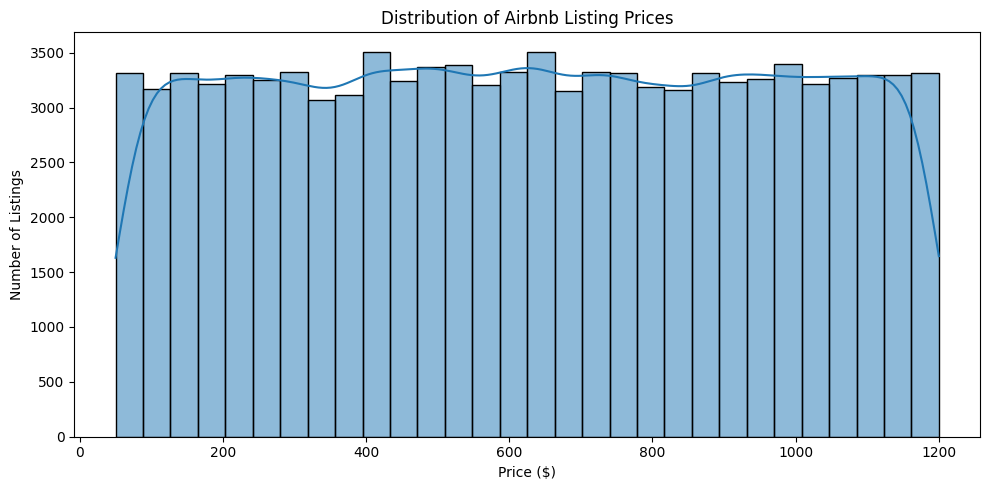

In [37]:
import matplotlib.pyplot as plt
import seaborn as sns
plt.figure(figsize=(10, 5))
sns.histplot(
    data=df_analysis,
    x="price",
    bins=30,
    kde=True
)
plt.title("Distribution of Airbnb Listing Prices")
plt.xlabel("Price ($)")
plt.ylabel("Number of Listings")
plt.tight_layout()
plt.show()

Average price by room type:
room type
Hotel room         661.41
Shared room        634.43
Entire home/apt    626.05
Private room       624.73
Name: price, dtype: float64


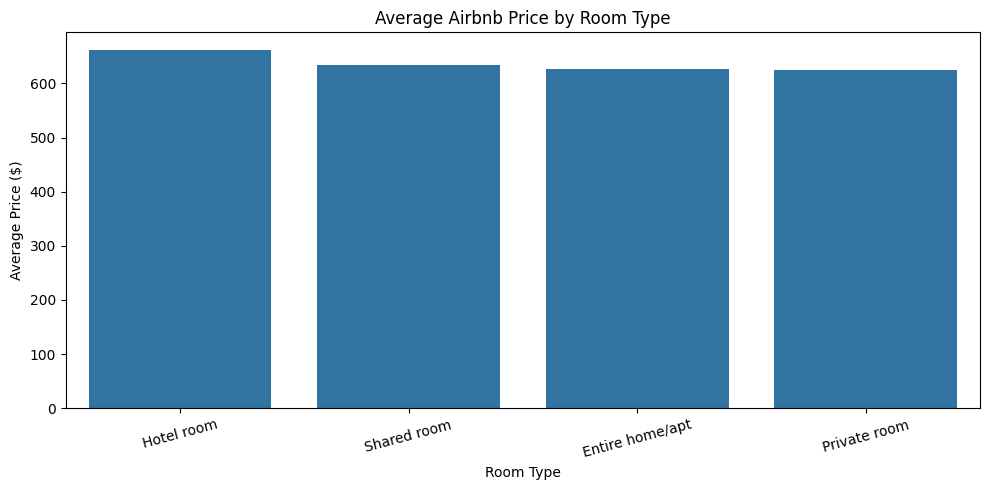

In [38]:
room_prices = (
    df_analysis.groupby("room type")["price"]
    .mean()
    .sort_values(ascending=False)
)
print("Average price by room type:")
print(room_prices.round(2))
plt.figure(figsize=(10, 5))
sns.barplot(
    x=room_prices.index,
    y=room_prices.values
)
plt.title("Average Airbnb Price by Room Type")
plt.xlabel("Room Type")
plt.ylabel("Average Price ($)")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

Average price by neighbourhood group:
neighbourhood group
Queens           629.79
Bronx            627.97
Brooklyn         626.44
Staten Island    624.72
Manhattan        623.53
brookln          580.00
Name: price, dtype: float64


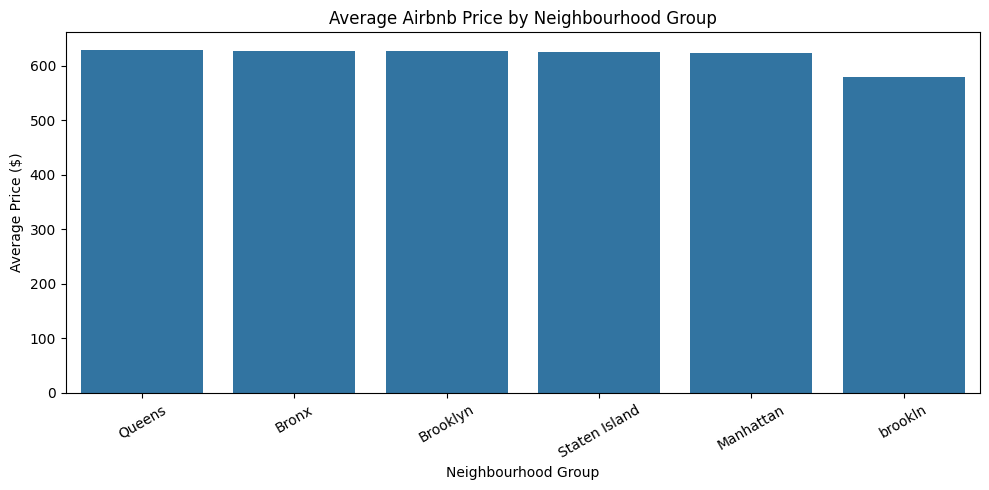

In [39]:
neighbourhood_prices = (
    df_analysis.groupby("neighbourhood group")["price"]
    .mean()
    .sort_values(ascending=False)
)
print("Average price by neighbourhood group:")
print(neighbourhood_prices.round(2))
plt.figure(figsize=(10, 5))
sns.barplot(
    x=neighbourhood_prices.index,
    y=neighbourhood_prices.values
)
plt.title("Average Airbnb Price by Neighbourhood Group")
plt.xlabel("Neighbourhood Group")
plt.ylabel("Average Price ($)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

Corrected average prices:
neighbourhood group
Queens           629.79
Bronx            627.97
Brooklyn         626.44
Staten Island    624.72
Manhattan        623.53
Name: price, dtype: float64


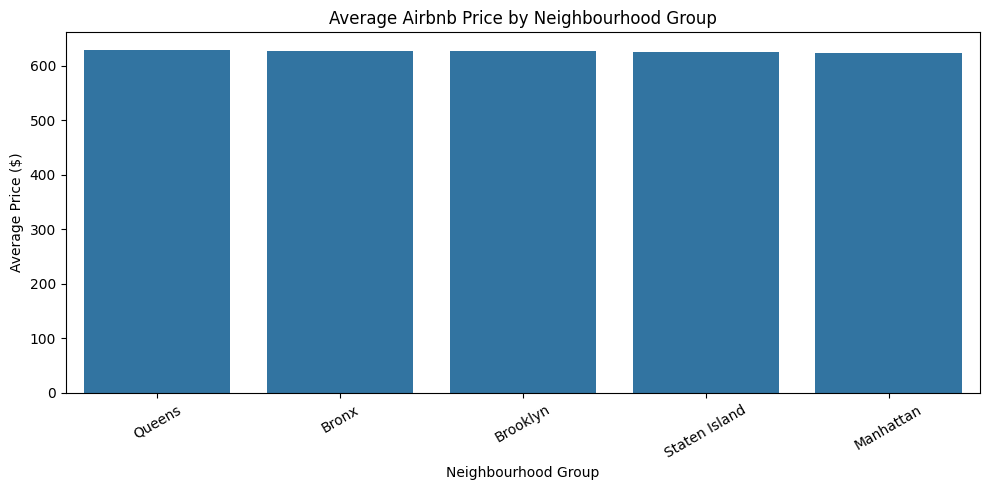

In [40]:
df_analysis["neighbourhood group"] = (
    df_analysis["neighbourhood group"]
    .replace({
        "brookln": "Brooklyn",
        "Brooklyn": "Brooklyn"
    })
)
neighbourhood_prices = (
    df_analysis.groupby("neighbourhood group")["price"]
    .mean()
    .sort_values(ascending=False)
)
print("Corrected average prices:")
print(neighbourhood_prices.round(2))
plt.figure(figsize=(10, 5))
sns.barplot(
    x=neighbourhood_prices.index,
    y=neighbourhood_prices.values
)
plt.title("Average Airbnb Price by Neighbourhood Group")
plt.xlabel("Neighbourhood Group")
plt.ylabel("Average Price ($)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

Listings by room type:
room type
Entire home/apt    51384
Private room       44719
Shared room         2145
Hotel room           113
Name: count, dtype: int64


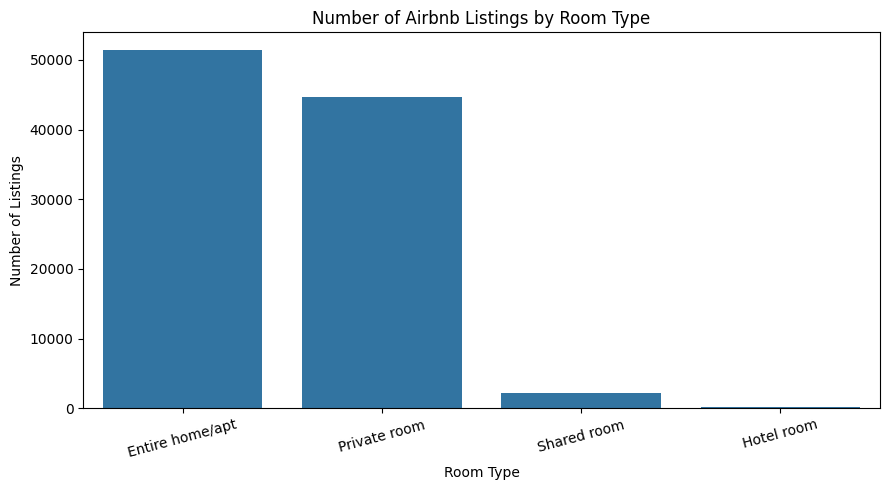

In [41]:
room_counts = df_analysis["room type"].value_counts()
print("Listings by room type:")
print(room_counts)
plt.figure(figsize=(9, 5))
sns.barplot(
    x=room_counts.index,
    y=room_counts.values
)
plt.title("Number of Airbnb Listings by Room Type")
plt.xlabel("Room Type")
plt.ylabel("Number of Listings")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

In [42]:
print("FINAL AIRBNB ANALYSIS SUMMARY")
print("-" * 35)
print("Total listings:", len(df_analysis))
print("Total columns:", df_analysis.shape[1])
print("\nPrice statistics:")
print("Average price: $", round(df_analysis["price"].mean(), 2))
print("Median price: $", round(df_analysis["price"].median(), 2))
print("Minimum price: $", df_analysis["price"].min())
print("Maximum price: $", df_analysis["price"].max())
print("\nMost common room type:")
print(df_analysis["room type"].value_counts().idxmax())
print("\nAverage price by room type:")
print(
    df_analysis.groupby("room type")["price"]
    .mean()
    .round(2)
)
print("\nListings by neighbourhood group:")
print(df_analysis["neighbourhood group"].value_counts())

FINAL AIRBNB ANALYSIS SUMMARY
-----------------------------------
Total listings: 98361
Total columns: 25

Price statistics:
Average price: $ 625.67
Median price: $ 625.0
Minimum price: $ 50.0
Maximum price: $ 1200.0

Most common room type:
Entire home/apt

Average price by room type:
room type
Entire home/apt    626.05
Hotel room         661.41
Private room       624.73
Shared room        634.43
Name: price, dtype: float64

Listings by neighbourhood group:
neighbourhood group
Manhattan        41783
Brooklyn         40105
Queens           12878
Bronx             2644
Staten Island      924
Name: count, dtype: int64


In [44]:
output_file = "airbnb_cleaned_analysis.csv"
df_analysis.to_csv(output_file, index=False)
print("Cleaned dataset saved as:", output_file)
print("Rows exported:", len(df_analysis))
print("Columns exported:", len(df_analysis.columns))

Cleaned dataset saved as: airbnb_cleaned_analysis.csv
Rows exported: 98361
Columns exported: 25


In [45]:

from google.colab import files

files.download("airbnb_cleaned_analysis.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>